# Notebook 03: Comparing models

**Goal:** find out whether a different classifier beats our Logistic Regression baseline, and tune the most promising one.

**Input:** `data/processed/reviews_electronics_clean.csv`
**Output:** `reports/model_comparison.csv`, `reports/model_comparison.png`, and the best model saved in `models/`

**What we do, in order**
1. Rebuild the same train/test split and TF-IDF features as notebook 02 (same settings, so scores are comparable)
2. Train three models: Logistic Regression, Complement Naive Bayes, Linear SVM
3. Compare them on the normal and strict test sets
4. Tune the Linear SVM with cross-validation
5. Pick the best model and save it

**Fair comparison rule:** every model sees exactly the same training data, the same features and the same test data. Only the algorithm changes.

## Step 0: Setup

In [1]:
import os, sys, time
root = os.getcwd() if os.path.isdir("src") else os.path.abspath("..")
os.chdir(root)
sys.path.insert(0, root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
import joblib

LABELS = ["negative", "neutral", "positive"]

## Step 1: Same split and features as notebook 02

We repeat the split with the **same** `random_state=42` and the same TF-IDF settings. That guarantees the test reviews are identical, so differences in score come only from the model.

In [2]:
elec = pd.read_csv("data/processed/reviews_electronics_clean.csv")
elec = elec.dropna(subset=["clean_text"])

train, test = train_test_split(elec, test_size=0.2,
                               stratify=elec["label"], random_state=42)
strict_test = test[~test["clean_text"].isin(set(train["clean_text"]))]
print("train:", len(train), " test:", len(test), " strict test:", len(strict_test))

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000)
X_train = vec.fit_transform(train["clean_text"])
X_test = vec.transform(test["clean_text"])
X_strict = vec.transform(strict_test["clean_text"])
y_train, y_test, y_strict = train["label"], test["label"], strict_test["label"]

train: 53920  test: 13481  strict test: 7621


## Step 2: The three candidates

| Model | Idea in one line | Why try it |
|---|---|---|
| **Logistic Regression** | Learns a weight per word; adds the weights up to score each class | Our baseline; easy to explain |
| **Complement Naive Bayes** | Uses word-count statistics per class (assumes words are independent); the "complement" version is designed for imbalanced text data | Very fast; a classic for text and a good fit for our imbalance |
| **Linear SVM** | Finds the best straight boundary that separates the classes with the widest margin | Often the strongest simple model on TF-IDF features |

`class_weight="balanced"` makes mistakes on rare classes cost more (not available for Naive Bayes, which handles imbalance in its own way).

In [3]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Complement Naive Bayes": ComplementNB(),
    "Linear SVM": LinearSVC(class_weight="balanced", max_iter=5000),
}

def score(y_true, y_pred):
    """Accuracy, macro-F1 and the F1 of each class."""
    per_class = f1_score(y_true, y_pred, average=None, labels=LABELS)
    return {"accuracy": round(accuracy_score(y_true, y_pred), 3),
            "macro_F1": round(f1_score(y_true, y_pred, average="macro"), 3),
            "F1_negative": round(per_class[0], 3),
            "F1_neutral": round(per_class[1], 3),
            "F1_positive": round(per_class[2], 3)}

rows, fitted = [], {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    seconds = round(time.time() - start, 1)
    fitted[name] = model
    rows.append({"model": name, "test_set": "normal", "train_seconds": seconds,
                 **score(y_test, model.predict(X_test))})
    rows.append({"model": name, "test_set": "strict", "train_seconds": seconds,
                 **score(y_strict, model.predict(X_strict))})

results = pd.DataFrame(rows)
display(results)

,model,test_set,train_seconds,accuracy,macro_F1,F1_negative,F1_neutral,F1_positive
0,Logistic Regression,normal,1.6,0.791,0.659,0.814,0.285,0.878
1,Logistic Regression,strict,1.6,0.801,0.660,0.787,0.301,0.891
2,Complement Naive Bayes,normal,0.1,0.861,0.638,0.767,0.215,0.932
3,Complement Naive Bayes,strict,0.1,0.829,0.617,0.739,0.199,0.914
4,Linear SVM,normal,3.9,0.875,0.678,0.815,0.280,0.939
5,Linear SVM,strict,3.9,0.844,0.654,0.782,0.258,0.923


**How to read this table**
- Compare **macro_F1** first (the fair headline number), then **F1_neutral** (our weak class).
- A model with higher accuracy but lower macro-F1 is usually just leaning toward "positive".
- `train_seconds` shows the cost: Naive Bayes is usually almost instant.
- If a model scores about the same on `normal` and `strict`, it is not just memorising repeated phrases.

## Step 3: Chart the comparison

A picture is easier to present than a table. The chart is saved in `reports/` so you can use it in your report and slides.

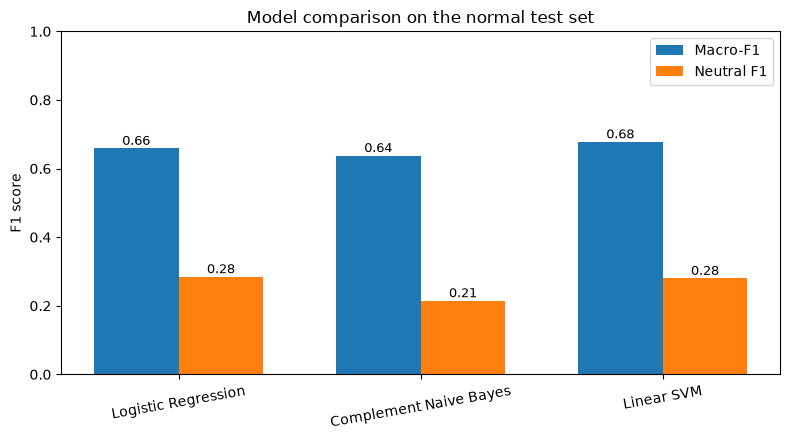

In [4]:
normal = results[results["test_set"] == "normal"].set_index("model")
x = np.arange(len(normal))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width/2, normal["macro_F1"], width, label="Macro-F1")
ax.bar(x + width/2, normal["F1_neutral"], width, label="Neutral F1")
ax.set_xticks(x)
ax.set_xticklabels(normal.index, rotation=10)
ax.set_ylim(0, 1)
ax.set_ylabel("F1 score")
ax.set_title("Model comparison on the normal test set")
ax.legend()
for i, v in enumerate(normal["macro_F1"]):
    ax.text(i - width/2, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
for i, v in enumerate(normal["F1_neutral"]):
    ax.text(i + width/2, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
plt.tight_layout()

os.makedirs("reports", exist_ok=True)
fig.savefig("reports/model_comparison.png", dpi=150)
plt.show()

## Step 4: Tune the Linear SVM

Every model has **hyperparameters**: settings we choose *before* training. For the SVM the main one is `C`, which controls how strictly the model tries to fit the training data (a very large `C` can overfit, a very small one underfits).

We try several values of `C` with **cross-validation**: the training data is split into 3 parts, and each part takes a turn as a mini test set while the model trains on the other two. We average the 3 scores. This means we choose `C` using the **training data only**, so the real test set stays untouched.

We score with `f1_macro`, because that is our headline metric.

In [5]:
grid = GridSearchCV(
    LinearSVC(class_weight="balanced", max_iter=5000),
    param_grid={"C": [0.05, 0.1, 0.3, 1.0]},
    scoring="f1_macro", cv=3, n_jobs=-1,
)
grid.fit(X_train, y_train)

print("best C:", grid.best_params_["C"])
print("cross-validated macro-F1:", round(grid.best_score_, 3))
pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score"]].round(3)

best C: 0.1
cross-validated macro-F1: 0.682


,param_C,mean_test_score
0,0.05,0.676
1,0.10,0.682
2,0.30,0.680
3,1.00,0.672


In [6]:
tuned_svm = grid.best_estimator_

tuned_rows = [
    {"model": "Linear SVM (tuned)", "test_set": "normal", "train_seconds": np.nan,
     **score(y_test, tuned_svm.predict(X_test))},
    {"model": "Linear SVM (tuned)", "test_set": "strict", "train_seconds": np.nan,
     **score(y_strict, tuned_svm.predict(X_strict))},
]
results = pd.concat([results, pd.DataFrame(tuned_rows)], ignore_index=True)
results.sort_values(["test_set", "macro_F1"], ascending=[True, False])

,model,test_set,train_seconds,accuracy,macro_F1,F1_negative,F1_neutral,F1_positive
6,Linear SVM (tuned),normal,NaN,0.883,0.686,0.828,0.287,0.943
4,Linear SVM,normal,3.9,0.875,0.678,0.815,0.280,0.939
0,Logistic Regression,normal,1.6,0.791,0.659,0.814,0.285,0.878
2,Complement Naive Bayes,normal,0.1,0.861,0.638,0.767,0.215,0.932
7,Linear SVM (tuned),strict,NaN,0.861,0.674,0.805,0.288,0.930
1,Logistic Regression,strict,1.6,0.801,0.660,0.787,0.301,0.891
5,Linear SVM,strict,3.9,0.844,0.654,0.782,0.258,0.923
3,Complement Naive Bayes,strict,0.1,0.829,0.617,0.739,0.199,0.914


**What to notice:** tuning usually gives a small gain, not a miracle. If the tuned model is only slightly better, that is a useful finding too: it tells us the limit comes from the data (label noise, the neutral class) more than from the algorithm.

## Step 5: Pick the best model and look closer

We take the model with the highest macro-F1 on the normal test set and print its full report.

In [7]:
all_models = {**fitted, "Linear SVM (tuned)": tuned_svm}
best_name = (results[results["test_set"] == "normal"]
             .sort_values("macro_F1", ascending=False).iloc[0]["model"])
best_model = all_models[best_name]
print("Best model:", best_name)

print(classification_report(y_test, best_model.predict(X_test), digits=3))

Best model: Linear SVM (tuned)
              precision    recall  f1-score   support

    negative      0.807     0.851     0.828      1986
     neutral      0.342     0.247     0.287      1008
    positive      0.935     0.951     0.943     10487

    accuracy                          0.883     13481
   macro avg      0.695     0.683     0.686     13481
weighted avg      0.872     0.883     0.877     13481



**Reminder:** look at the **neutral** row. If neutral recall is decent but precision is low, the model labels too many reviews as neutral. If you want to push further, the next ideas are: adjusting the decision threshold for neutral, merging classes (positive vs not-positive), or a transformer model that understands context.

## Step 6: Save results and the best model

In [8]:
results.to_csv("reports/model_comparison.csv", index=False)

os.makedirs("models", exist_ok=True)
joblib.dump((vec, best_model), "models/best_model.pkl")
print("saved reports/model_comparison.csv and models/best_model.pkl")

saved reports/model_comparison.csv and models/best_model.pkl


**Done.** Send the comparison table to whoever is helping you write the README, and copy the numbers into the results section. Next: aspect-based sentiment (what do customers like or dislike about battery, camera, price?) and then a transformer model.